In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

import matplotlib.pyplot as plt

df = pd.read_csv("../01 - DataPreparation/df_prepared.csv")

We use all correlation methods to extract significat features with GameWeight.

In [2]:
for corr_method in ['pearson', 'spearman', 'kendall']:
    print(df.corr(numeric_only=True, method=corr_method)['GameWeight'].sort_values(key=abs, ascending=False).head(10))
    print("="*80)

GameWeight           1.000000
AvgPlaytime_log      0.716753
AgeRec               0.634089
Cat:War              0.451530
NumWant_log          0.417958
Cat:Strategy         0.299984
MaxPlayers_log      -0.255949
NumWant              0.248581
NumExpansions_log    0.240796
Cat:Childrens       -0.220480
Name: GameWeight, dtype: float64
GameWeight         1.000000
AvgPlaytime_log    0.714675
AvgPlaytime        0.714675
AgeRec             0.670386
NumWant            0.436899
NumWant_log        0.436899
Cat:War            0.436379
Cat:Strategy       0.308550
MaxPlayers_log    -0.294023
MaxPlayers        -0.294023
Name: GameWeight, dtype: float64
GameWeight         1.000000
AvgPlaytime_log    0.544901
AvgPlaytime        0.544901
AgeRec             0.505068
Cat:War            0.360362
NumWant            0.305472
NumWant_log        0.305472
Cat:Strategy       0.254801
MaxPlayers_log    -0.218693
MaxPlayers        -0.218693
Name: GameWeight, dtype: float64


In [3]:
feature_cols = ['AvgPlaytime_log', 'AgeRec', 'Cat:War', 'NumWant_log']

In [4]:
X = df[feature_cols].copy()
y = df['GameWeight'].copy()

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [6]:
lin_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

In [7]:
lin_pipe.fit(X_train, y_train)
y_pred = lin_pipe.predict(X_test)

r2 = r2_score(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("Baseline LinearRegression")
print(f"R^2  : {r2:.3f}")
print(f"RMSE : {rmse:.3f}")
print(f"MAE  : {mae:.3f}")

Baseline LinearRegression
R^2  : 0.615
RMSE : 0.494
MAE  : 0.381


Baseline Linear Regression achieves moderate predictive power on GameWeight (R² = 0.615), with RMSE = 0.494 and MAE = 0.381, meaning it captures a decent share of variance but still has noticeable average error per prediction.

In [16]:
coefs = lin_pipe.named_steps["model"].coef_
intercept = lin_pipe.named_steps["model"].intercept_

# One-line equation (scaled features)
terms = [f"{c:.4f}*{name}" for name, c in zip(feature_cols, coefs)]
equation = f"GameWeight = {intercept:.4f} + " + " + ".join(terms)
print(equation)

GameWeight = 2.0410 + 0.3593*AvgPlaytime_log + 0.2081*AgeRec + 0.0590*Cat:War + 0.1808*NumWant_log


This equation is the learned linear relationship (on standardized features): GameWeight starts at 2.0410, then increases most with AvgPlaytime_log (0.3593), followed by AgeRec (0.2081) and NumWant_log (0.1808); Cat:War (0.0590) has a smaller positive effect.

In [ ]:
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, KFold

from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

param_grid = [
    {
        "model": [Ridge()],
        "model__alpha": np.logspace(-6, 6, 25),
        "model__fit_intercept": [True, False],
        "model__tol": [1e-6, 1e-5, 1e-4, 1e-3],
        "model__solver": ["auto"],
    },
    {
        "model": [Lasso(max_iter=100000)],
        "model__alpha": np.logspace(-2, 2, 41),
        "model__fit_intercept": [True, False],
        "model__tol": [1e-5, 1e-4, 1e-3],
        "model__selection": ["cyclic", "random"],
    },
    {
        "model": [ElasticNet(max_iter=100000)],
        "model__alpha": np.logspace(-2, 2, 41),
        "model__l1_ratio": [0.05, 0.1, 0.3, 0.5, 0.7, 0.9, 0.95],
        "model__fit_intercept": [True, False],
        "model__tol": [1e-5, 1e-4, 1e-3],
        "model__selection": ["cyclic", "random"],
    },
    {"model":[LinearRegression()]}
]

cv = KFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    pipe,
    param_grid=param_grid,
    cv=cv,
    scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"},
    refit="rmse",
    n_jobs=-1,
)

grid.fit(X_train, y_train)

best_model = grid.best_estimator_.named_steps["model"]
best_i = grid.best_index_

print("\nBest Model:", best_model.__class__.__name__)
print("Best Params:", grid.best_params_)
print("Best CV RMSE:", round(-grid.best_score_, 3))
print("CV R^2 at best RMSE:", round(grid.cv_results_["mean_test_r2"][best_i], 3))



Best Model: Ridge
Best Params: {'model': Ridge(), 'model__alpha': np.float64(10.0), 'model__fit_intercept': True, 'model__solver': 'auto', 'model__tol': 1e-06}
Best CV RMSE: 0.497
CV R^2 at best RMSE: 0.613


Among Linear, Ridge, Lasso, and ElasticNet, Ridge performed best, with alpha = 10 providing the right amount of regularization. It achieves a CV RMSE of 0.497 and CV R² ≈ 0.613, essentially matching the baseline linear model while slightly improving stability against overfitting/multicollinearity.

In [12]:
y_pred = grid.best_estimator_.predict(X_test)

rmse_test = np.sqrt(mean_squared_error(y_test, y_pred))
mae_test = mean_absolute_error(y_test, y_pred)

print("\nTest Performance")
print(f"R^2  : {r2_score(y_test, y_pred):.3f}")
print(f"RMSE : {rmse_test:.3f}")
print(f"MAE  : {mae_test:.3f}")


Test Performance
R^2  : 0.615
RMSE : 0.494
MAE  : 0.381


On the test set, the best (Ridge) model delivers R² = 0.615, RMSE = 0.494, and MAE = 0.381, essentially matching the baseline linear regression—so regularization improves robustness but doesn’t materially change predictive accuracy with these 4 features.

In [17]:
best_est = grid.best_estimator_
best_model = best_est.named_steps["model"]

coefs = best_model.coef_
intercept = best_model.intercept_

# One-line equation (scaled features)
terms = [f"{c:.4f}*{name}" for name, c in zip(feature_cols, coefs)]
equation = f"GameWeight = {intercept:.4f} + " + " + ".join(terms)

print(f"Best Model (scaled X): {best_model.__class__.__name__}")
print(equation)


Best Model (scaled X): Ridge
GameWeight = 2.0410 + 0.3590*AvgPlaytime_log + 0.2081*AgeRec + 0.0592*Cat:War + 0.1807*NumWant_log


The fitted equation (on standardized features) is very similar to the baseline: AvgPlaytime_log remains the strongest positive driver (0.3590), followed by AgeRec (0.2081) and NumWant_log (0.1807), while Cat:War has a smaller positive effect (0.0592).

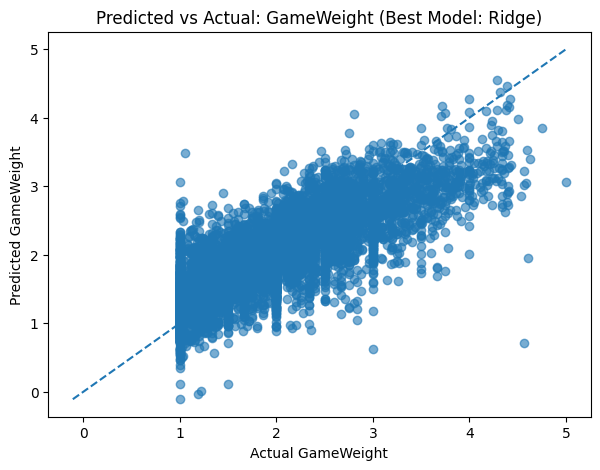

In [14]:
best_est = grid.best_estimator_
model_name = best_est.named_steps["model"].__class__.__name__

y_pred = best_est.predict(X_test)

plt.figure(figsize=(7,5))
plt.scatter(y_test, y_pred, alpha=0.6)
mn = min(y_test.min(), y_pred.min())
mx = max(y_test.max(), y_pred.max())
plt.plot([mn, mx], [mn, mx], linestyle="--")
plt.xlabel("Actual GameWeight")
plt.ylabel("Predicted GameWeight")
plt.title(f"Predicted vs Actual: GameWeight (Best Model: {model_name})")
plt.show()

Low GameWeight is slightly overpredicted and high GameWeight is underpredicted, with noticeable scatter around the diagonal.

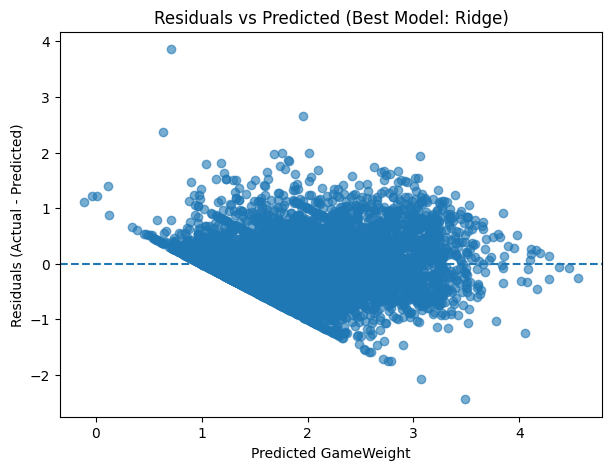

In [15]:
best_est = grid.best_estimator_
model_name = best_est.named_steps["model"].__class__.__name__

y_pred = best_est.predict(X_test)
resid = y_test - y_pred

plt.figure(figsize=(7,5))
plt.scatter(y_pred, resid, alpha=0.6)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted GameWeight")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title(f"Residuals vs Predicted (Best Model: {model_name})")
plt.show()

Residuals are mostly centered near 0, but show a mild pattern (more positive residuals at low predictions and more negative residuals at high predictions), indicating systematic shrinkage at the extremes and some uneven error spread.